In [1]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from pathlib import Path
import csv
import json

## Данные и их подготовка


In [2]:
X, y = make_moons(n_samples=2400 ,noise=0.25 , random_state=2026)

In [3]:
X.shape

(2400, 2)

In [4]:
y.shape

(2400,)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2026, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=2026, stratify=y_train)

In [6]:
# скейлим 
scaler = StandardScaler()
#X_train = scaler.fit_transform(X_train)
#X_val = scaler.fit_transform(X_val)
#X_test = scaler.fit_transform(X_test)
scaler.fit(X_train)
X_scaled_train = scaler.transform(X_train)
X_scaled_val = scaler.transform(X_val)
X_scaled_test = scaler.transform(X_test)

In [7]:
X_scaled_train.shape

(1440, 2)

In [8]:
print(np.mean(X_scaled_train,axis=0))
print(np.std(X_scaled_train, axis=0))

[2.06624841e-17 6.21570696e-16]
[1. 1.]


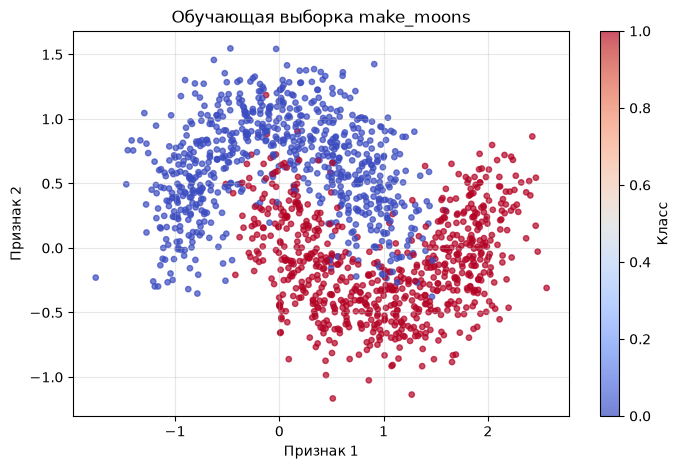

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    s=15,
    alpha=0.7
)

plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Обучающая выборка make_moons")
plt.colorbar(label="Класс")
plt.grid(alpha=0.3)
plt.show()

In [10]:
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    classes, counts = np.unique(labels, return_counts=True)
    print(name, dict(zip(classes, counts)))


Train {np.int64(0): np.int64(720), np.int64(1): np.int64(720)}
Validation {np.int64(0): np.int64(240), np.int64(1): np.int64(240)}
Test {np.int64(0): np.int64(240), np.int64(1): np.int64(240)}


## MLP


In [11]:
## содадим класс

class MyTinyMLP(nn.Module):
    def __init__(self, number_hidden_layers, nonlinearity, initialization):
        super().__init__()
        self.linears = nn.ModuleList()
        self.linears.append(nn.Linear(2,32))

        for i in range(number_hidden_layers - 1):
            self.linears.append(nn.Linear(32,32))
        self.head = nn.Linear(32, 2)
        
        self.nonlinearity = nonlinearity
        self.initialization = initialization
        self.initialize_weights()
       

    def initialize_weights(self):
        for layer in self.linears:
            if self.initialization == "xavier":
                nn.init.xavier_normal_(layer.weight, gain=1.0)
    
            elif self.initialization == "he":
                nn.init.kaiming_normal_(
                    layer.weight,
                    mode="fan_in",
                    nonlinearity="relu"
                )
    
            nn.init.zeros_(layer.bias)
    
        nn.init.xavier_normal_(self.head.weight, gain=1.0)
        nn.init.zeros_(self.head.bias)
        

    def forward(self, x):

        for layer in self.linears:
            x = layer(x)
            x = self.nonlinearity(x)
        result = self.head(x)
        return result

    def make_prediction(self, x):
        result = self(x)
        return torch.argmax(result, dim=1)
        

## наш трейн


In [12]:
from torch.utils.data import DataLoader, TensorDataset

In [13]:
X = torch.as_tensor(X_scaled_train, device=torch.device("cpu"), dtype=torch.float32)
y = torch.as_tensor(y_train, device=torch.device("cpu"), dtype=torch.long)

dataset = TensorDataset(X, y)

seed = 1
def gen(seed):
    g_cpu = torch.Generator(device='cpu')
    g_cpu.manual_seed(10000 + seed)
    return g_cpu

loader = DataLoader(dataset, batch_size=128, shuffle = True, generator = gen(seed), drop_last=False)

In [14]:
def evaluate(model, X, y, loss_fn):
    model.eval()

    with torch.no_grad():
        logits = model(X)
        loss = loss_fn(logits, y)
        predictions = torch.argmax(logits, dim=1)
        accuracy = (predictions == y).float().mean()

    return loss.item(), accuracy.item()

def train_model(model, loader, X_train, y_train,
                X_val, y_val, optimizer, epochs=100, gradient_callback=None):

    loss_fn = nn.CrossEntropyLoss(reduction="mean")
    history = []

    def record_metrics(epoch):
        if gradient_callback is not None and epoch in (0, 20, 100):
            gradient_callback(model, epoch)
        
        train_loss, train_acc = evaluate(
            model, X_train, y_train, loss_fn
        )
        val_loss, val_acc = evaluate(
            model, X_val, y_val, loss_fn
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

    record_metrics(0)

    for epoch in range(1, epochs + 1):
        model.train()

        for xb, yb in loader:
            optimizer.zero_grad()

            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()

        record_metrics(epoch)

    return history

## Первый запуск MyTinyMLP(6, nn.ReLU(), "he")

In [15]:
gradient_results = []

def gradient_callback(model, epoch):
    norms = measure_gradients(model)

    for layer, norm in norms.items():
        gradient_results.append({
            "config": "D",
            "seed": 11,
            "epoch": epoch,
            "layer": layer,
            "gradient_norm": norm
        })

In [16]:
torch.set_num_threads(1)

seed = 11
torch.manual_seed(seed)

Xtr = torch.as_tensor(X_scaled_train, dtype=torch.float32)
ytr = torch.as_tensor(y_train, dtype=torch.long)

Xv = torch.as_tensor(X_scaled_val, dtype=torch.float32)
yv = torch.as_tensor(y_val, dtype=torch.long)

dataset = TensorDataset(Xtr, ytr)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    generator=torch.Generator().manual_seed(10000 + seed),
    drop_last=False
)

xb = Xtr[:128]
yb = ytr[:128]

def measure_gradients(model):


    model.eval()
    model.zero_grad()

    pred = model(xb)
    loss = nn.CrossEntropyLoss(reduction='mean')(pred, yb)
    loss.backward()

    dict_ = {}
    k = 0
    for layer in model.linears:
        k += 1
        gradient = layer.weight.grad
        norm_matr = torch.linalg.matrix_norm(gradient).item()
        dict_[k] = norm_matr

    model.zero_grad()
    return dict_

model = MyTinyMLP(6, nn.ReLU(), "he")

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.003
)

history = train_model(
    model, loader,
    Xtr, ytr,
    Xv, yv,
    optimizer,
    epochs=100,
    gradient_callback=gradient_callback
)

print(history[-1])

{'epoch': 100, 'train_loss': 0.1087748184800148, 'train_accuracy': 0.9534721970558167, 'val_loss': 0.21231187880039215, 'val_accuracy': 0.9229166507720947}


In [17]:
for record in gradient_results:
    print(record)

print("Количество измерений:", len(gradient_results))

{'config': 'D', 'seed': 11, 'epoch': 0, 'layer': 1, 'gradient_norm': 0.308774471282959}
{'config': 'D', 'seed': 11, 'epoch': 0, 'layer': 2, 'gradient_norm': 1.399954915046692}
{'config': 'D', 'seed': 11, 'epoch': 0, 'layer': 3, 'gradient_norm': 1.4979779720306396}
{'config': 'D', 'seed': 11, 'epoch': 0, 'layer': 4, 'gradient_norm': 1.4003373384475708}
{'config': 'D', 'seed': 11, 'epoch': 0, 'layer': 5, 'gradient_norm': 2.413848638534546}
{'config': 'D', 'seed': 11, 'epoch': 0, 'layer': 6, 'gradient_norm': 4.038586139678955}
{'config': 'D', 'seed': 11, 'epoch': 20, 'layer': 1, 'gradient_norm': 0.0477074459195137}
{'config': 'D', 'seed': 11, 'epoch': 20, 'layer': 2, 'gradient_norm': 0.17064587771892548}
{'config': 'D', 'seed': 11, 'epoch': 20, 'layer': 3, 'gradient_norm': 0.1401098668575287}
{'config': 'D', 'seed': 11, 'epoch': 20, 'layer': 4, 'gradient_norm': 0.1328093558549881}
{'config': 'D', 'seed': 11, 'epoch': 20, 'layer': 5, 'gradient_norm': 0.1153222918510437}
{'config': 'D', 'se

## Все 12 запусков 


#### функция измерения градиентов


In [18]:
CONFIGS = {
    "A": (6, nn.Sigmoid, "xavier", "adam", 0.003),
    "B": (6, nn.Tanh,    "xavier", "adam", 0.003),
    "C": (6, nn.ReLU,    "xavier", "adam", 0.003),
    "D": (6, nn.ReLU,    "he",     "adam", 0.003),
    "E": (6, nn.ReLU,    "he",     "sgd",  0.05),
    "F": (1, nn.ReLU,    "he",     "adam", 0.003),
}

In [19]:
def run_experiment(config, seed):
    n_layers, activation, initialization, opt_name, lr = CONFIGS[config]
    
    torch.manual_seed(seed)
    
    model = MyTinyMLP(
        n_layers,
        activation(),
        initialization
    )
    
    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=True,
        generator=gen(seed),
        drop_last=False
    )
    if opt_name == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(
            model.parameters(), lr=lr, momentum=0
        )

    gradients = []

    def callback(model, epoch):
        norms = measure_gradients(model)

        for layer, norm in norms.items():
            gradients.append({
                "config": config,
                "seed": seed,
                "epoch": epoch,
                "layer": layer,
                "gradient_norm": norm
            })

    gradient_fn = callback if config in ("A", "C", "D") else None
    
    history = train_model(
        model, loader,
        Xtr, ytr,
        Xv, yv,
        optimizer,
        epochs=100,
        gradient_callback=gradient_fn
    )

    # Добавляем информацию о запуске к каждой эпохе
    for record in history:
        record["config"] = config
        record["seed"] = seed

    return model, history, gradients

In [20]:
torch.set_num_threads(1)

all_metrics = []
all_gradients = []
trained_models = {}

for config in CONFIGS:
    for seed in (11, 29):

        model, history, gradients = run_experiment(config, seed)

        trained_models[(config, seed)] = model

        all_metrics.extend(history)
        all_gradients.extend(gradients)

        print(
            config,
            seed,
            "val_loss:",
            round(history[-1]["val_loss"], 5),
            "val_accuracy:",
            round(history[-1]["val_accuracy"], 5)
        )

print("Всего метрик:", len(all_metrics))
print("Всего измерений градиентов:", len(all_gradients))

A 11 val_loss: 0.19075 val_accuracy: 0.91667
A 29 val_loss: 0.1771 val_accuracy: 0.91667
B 11 val_loss: 0.2034 val_accuracy: 0.9125
B 29 val_loss: 0.18927 val_accuracy: 0.91875
C 11 val_loss: 0.18069 val_accuracy: 0.92083
C 29 val_loss: 0.22408 val_accuracy: 0.91042
D 11 val_loss: 0.21231 val_accuracy: 0.92292
D 29 val_loss: 0.20634 val_accuracy: 0.91458
E 11 val_loss: 0.34613 val_accuracy: 0.85833
E 29 val_loss: 0.35574 val_accuracy: 0.83958
F 11 val_loss: 0.16779 val_accuracy: 0.92917
F 29 val_loss: 0.16762 val_accuracy: 0.92292
Всего метрик: 1212
Всего измерений градиентов: 108


## Сохраним все 


In [21]:
Path("results").mkdir(exist_ok=True)

def save_csv(path, records):
    with open(path, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file,
            fieldnames=records[0].keys()
        )
        writer.writeheader()
        writer.writerows(records)

save_csv("results/metrics.csv", all_metrics)
save_csv("results/gradients.csv", all_gradients)

In [22]:
print("Рабочая директория:", Path.cwd())

for name in ["metrics.csv", "gradients.csv"]:
    path = Path("results") / name

    print("Файл:", path.resolve())
    print("Существует:", path.exists())

    if path.exists():
        print("Размер:", path.stat().st_size, "байт")

Рабочая директория: /Users/andrew/ml
Файл: /Users/andrew/ml/results/metrics.csv
Существует: True
Размер: 103026 байт
Файл: /Users/andrew/ml/results/gradients.csv
Существует: True
Размер: 3365 байт


## графики


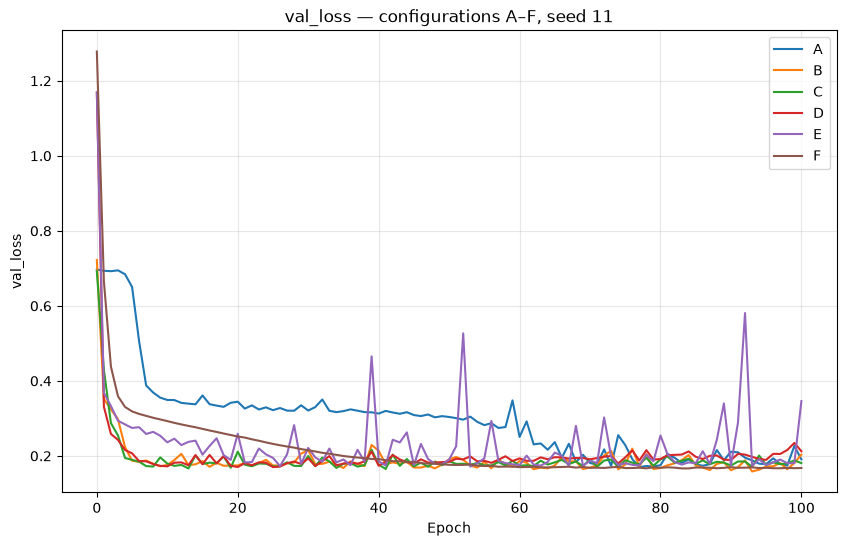

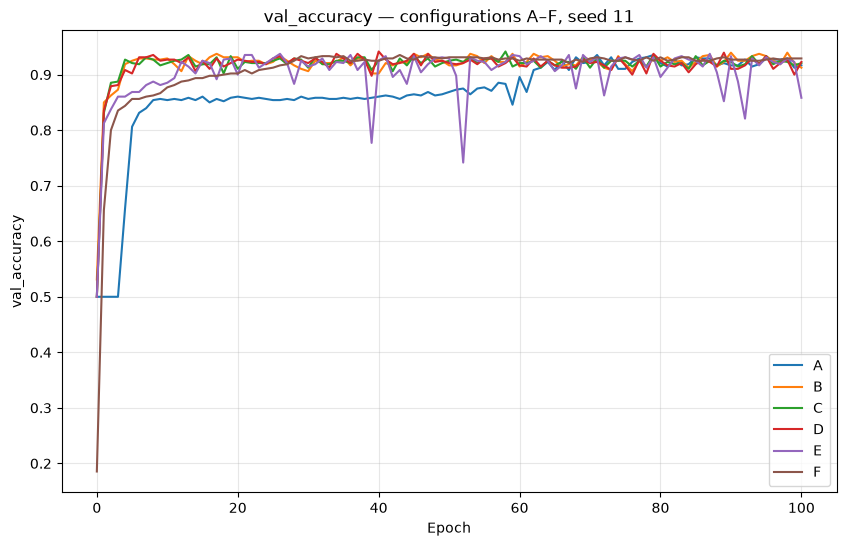

In [23]:
Path("figures").mkdir(exist_ok=True)

for metric in ("val_loss", "val_accuracy"):
    plt.figure(figsize=(10, 6))

    for config in CONFIGS:
        records = [
            record for record in all_metrics
            if record["config"] == config
            and record["seed"] == 11
        ]

        records.sort(key=lambda r: r["epoch"])

        epochs = [r["epoch"] for r in records]
        values = [r[metric] for r in records]

        plt.plot(epochs, values, label=config)

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"{metric} — configurations A–F, seed 11")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(f"figures/{metric}.png", dpi=150)
    plt.show()

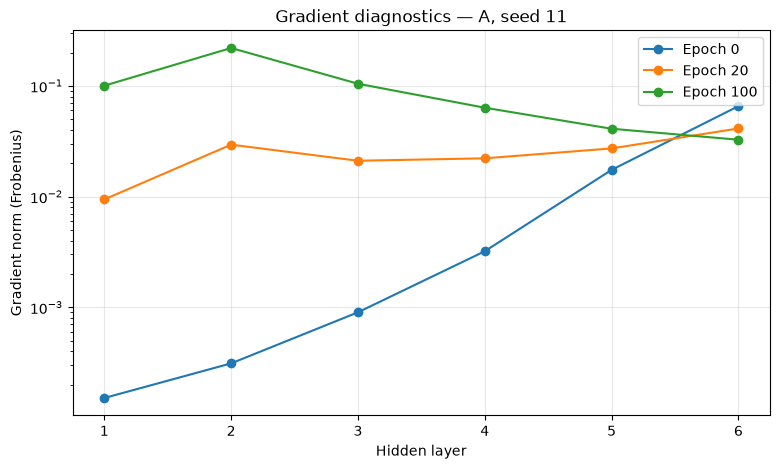

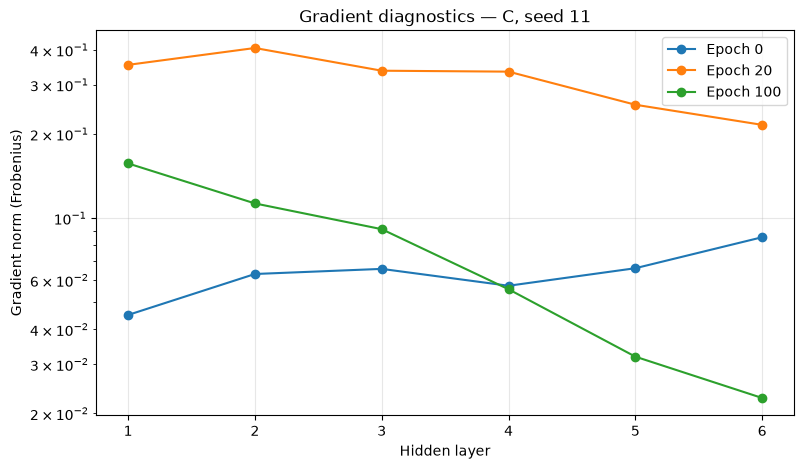

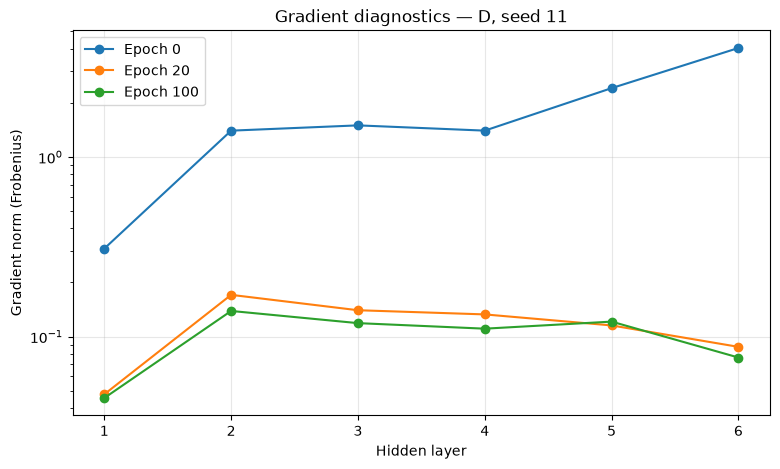

In [24]:
for config in ("A", "C", "D"):
    plt.figure(figsize=(9, 5))

    for epoch in (0, 20, 100):
        records = [
            r for r in all_gradients
            if r["config"] == config
            and r["seed"] == 11
            and r["epoch"] == epoch
        ]

        records.sort(key=lambda r: r["layer"])

        layers = [r["layer"] for r in records]

        norms = [
            r["gradient_norm"]
            if r["gradient_norm"] > 0 else np.nan
            for r in records
        ]

        plt.plot(
            layers,
            norms,
            marker="o",
            label=f"Epoch {epoch}"
        )

    plt.yscale("log")
    plt.xlabel("Hidden layer")
    plt.ylabel("Gradient norm (Frobenius)")
    plt.title(f"Gradient diagnostics — {config}, seed 11")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(
        f"figures/gradients_{config}.png",
        dpi=150
    )
    plt.show()

In [25]:
final_results = [
    r for r in all_metrics
    if r["epoch"] == 100
]

final_results.sort(
    key=lambda r: (r["config"], r["seed"])
)

for r in final_results:
    print(
        f'{r["config"]} | seed={r["seed"]} | '
        f'train_loss={r["train_loss"]:.4f} | '
        f'train_acc={r["train_accuracy"]:.4f} | '
        f'val_loss={r["val_loss"]:.4f} | '
        f'val_acc={r["val_accuracy"]:.4f}'
    )

A | seed=11 | train_loss=0.1505 | train_acc=0.9458 | val_loss=0.1908 | val_acc=0.9167
A | seed=29 | train_loss=0.1403 | train_acc=0.9458 | val_loss=0.1771 | val_acc=0.9167
B | seed=11 | train_loss=0.1467 | train_acc=0.9465 | val_loss=0.2034 | val_acc=0.9125
B | seed=29 | train_loss=0.1436 | train_acc=0.9486 | val_loss=0.1893 | val_acc=0.9187
C | seed=11 | train_loss=0.1208 | train_acc=0.9514 | val_loss=0.1807 | val_acc=0.9208
C | seed=29 | train_loss=0.1293 | train_acc=0.9458 | val_loss=0.2241 | val_acc=0.9104
D | seed=11 | train_loss=0.1088 | train_acc=0.9535 | val_loss=0.2123 | val_acc=0.9229
D | seed=29 | train_loss=0.1141 | train_acc=0.9521 | val_loss=0.2063 | val_acc=0.9146
E | seed=11 | train_loss=0.2546 | train_acc=0.8847 | val_loss=0.3461 | val_acc=0.8583
E | seed=29 | train_loss=0.3033 | train_acc=0.8653 | val_loss=0.3557 | val_acc=0.8396
F | seed=11 | train_loss=0.1367 | train_acc=0.9493 | val_loss=0.1678 | val_acc=0.9292
F | seed=29 | train_loss=0.1382 | train_acc=0.9493 | v

In [26]:
final_results = [r for r in all_metrics if r["epoch"] == 100]

mean_losses = {}

for config in CONFIGS:
    losses = [
        r["val_loss"]
        for r in final_results
        if r["config"] == config
    ]
    mean_losses[config] = sum(losses) / len(losses)


best_config = min(
    CONFIGS,
    key=lambda c: (mean_losses[c], c)
)

best_run = min(
    (r for r in final_results if r["config"] == best_config),
    key=lambda r: (r["val_loss"], r["seed"])
)

best_seed = best_run["seed"]
best_model = trained_models[(best_config, best_seed)]

print("Best configuration:", best_config)
print("Best seed:", best_seed)
print("Validation loss:", best_run["val_loss"])

Xt = torch.as_tensor(X_scaled_test, dtype=torch.float32)
yt = torch.as_tensor(y_test, dtype=torch.long)

loss_fn = nn.CrossEntropyLoss(reduction="mean")

test_loss, test_accuracy = evaluate(
    best_model, Xt, yt, loss_fn
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Best configuration: F
Best seed: 29
Validation loss: 0.16762325167655945
Test loss: 0.13138487935066223
Test accuracy: 0.949999988079071


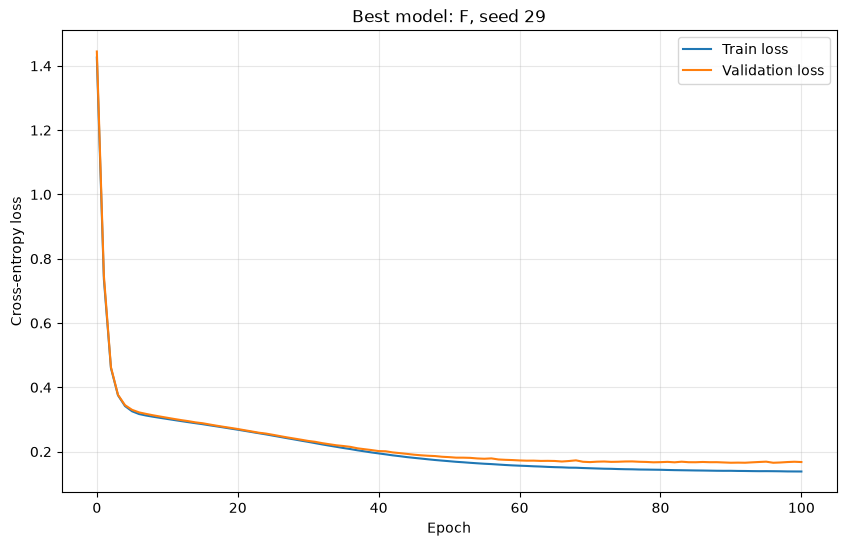

In [27]:
best_history = [
    r for r in all_metrics
    if r["config"] == best_config
    and r["seed"] == best_seed
]

best_history.sort(key=lambda r: r["epoch"])

plt.figure(figsize=(10, 6))

plt.plot(
    [r["epoch"] for r in best_history],
    [r["train_loss"] for r in best_history],
    label="Train loss"
)

plt.plot(
    [r["epoch"] for r in best_history],
    [r["val_loss"] for r in best_history],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title(f"Best model: {best_config}, seed {best_seed}")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("figures/best_model_loss.png", dpi=150)
plt.show()